---
title: "Understanding Account Churn and Lifetime Value"
author: "Fabian"
date: "2024-11-02"
categories: [Marketing]
format:
  html:
    code-fold: false
    toc: true
jupyter: python3
draft: True
---

Churn, also known as attrition or turnover, essentially measures how many customers stop doing business with you over a specific period. It's the opposite of customer retention.

Why is Churn Important?

Revenue Impact: Losing customers directly impacts your bottom line. High churn means reduced revenue and profitability.   
Customer Satisfaction: Churn can be a strong indicator of customer dissatisfaction. It suggests that your product, service, or overall customer experience isn't meeting expectations.   
Growth: Acquiring new customers is generally more expensive than retaining existing ones. High churn makes sustainable growth more challenging.   
Calculating Churn Rate

The basic formula for calculating churn rate is:

`Churn Rate = (Number of Customers Lost in a Period / Number of Customers at the Start of the Period) * 100`

Different Ways of Calculating Churn

Simple Churn Rate: This is the most basic calculation, as shown in the formula above. You can calculate it over any time frame (monthly, quarterly, annually).

Rolling Churn Rate: This provides a more dynamic view by calculating churn over a moving window (e.g., 90 days). It helps you see trends and fluctuations over time.

Cohort Analysis: This method groups customers based on when they started their relationship with you (e.g., all customers who signed up in January 2023). It allows you to track the churn rate of specific groups over time and identify patterns in customer behavior.

Revenue Churn Rate: Instead of counting customers, this focuses on the revenue lost due to churn. It's calculated as:
`Revenue Churn Rate = (Revenue Lost in a Period / Total Revenue at the Start of the Period) * 100`

Example: If your Monthly Recurring Revenue (MRR) at the start of the month was $10,000 and you lost $1,000 due to churn, your revenue churn rate would be ($1,000/$10,000) * 100 = 10%.

Factors Affecting Churn

Understanding what drives churn is crucial for developing effective retention strategies. Common factors include:

Poor customer service: Unresolved issues, long wait times, and unhelpful support can lead to frustration and churn.   
Lack of engagement: If customers aren't actively using your product or service, they're more likely to churn.
Pricing: Customers may find your pricing too high compared to competitors or perceive a lack of value.
Product issues: Bugs, lack of features, or a poor user experience can drive customers away.   
Competition: Attractive offers from competitors can entice customers to switch.

Understanding Account Churn and AB-LTV: A Data-Driven Approach for B2B Businesses
In the competitive B2B landscape, understanding the dynamics of customer relationships is paramount. Two key metrics that provide crucial insights into your business health are account churn rate and account-based lifetime value (AB-LTV).

This blog post will delve into these concepts, demonstrating how to calculate and visualize them using Python. We'll generate a realistic B2B dataset and explore techniques to analyze churn and AB-LTV, empowering you to make data-driven decisions for your business.

Generating a Realistic B2B Dataset
Let's start by creating a fictional dataset that mimics real-world B2B data. We'll use the faker library to generate company names, industries, and other relevant information.

In [1]:
import pandas as pd
import numpy as np
from faker import Faker
import datetime
from dateutil.relativedelta import relativedelta
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style for seaborn plots
sns.set_style("whitegrid")

fake = Faker()

# Function to generate a random date between a start and end date
def random_date(start, end):
    delta = end - start
    int_delta = (delta.days * 24 * 60 * 60) + delta.seconds
    random_second = np.random.randint(int_delta)
    return start + datetime.timedelta(seconds=random_second)

# Set parameters for data generation
num_accounts = 500
start_date = datetime.date(2020, 1, 1)
end_date = datetime.date(2024, 1, 1)

# Generate account data
accounts = []
for _ in range(num_accounts):
    account = {
        'account_id': fake.uuid4(),
        'company_name': fake.company(),
        'industry': fake.random_element(elements=('Technology', 'Finance', 'Healthcare', 'Manufacturing', 'Retail')),
        'employee_count': np.random.randint(10, 1000),
        'contract_start_date': random_date(start_date, end_date),
    }
    accounts.append(account)

# Convert to DataFrame
accounts_df = pd.DataFrame(accounts)

# Simulate contract end dates (churn)
churn_rate = 0.2  # Assume an overall churn rate of 20%
for index, row in accounts_df.iterrows():
    if np.random.rand() < churn_rate:
        # Ensure end_date is always AFTER start_date
        end_date_churn = min(row['contract_start_date'] + relativedelta(years=1), end_date) 
        accounts_df.loc[index, 'contract_end_date'] = random_date(row['contract_start_date'], end_date_churn)
    else:
        # Account still active: Set end date to None
        accounts_df.loc[index, 'contract_end_date'] = None 

# Generate invoice data (same as before)
invoices = []
for _, row in accounts_df.iterrows():
    # Generate 1-5 invoices per account
    num_invoices = np.random.randint(1, 6)
    for _ in range(num_invoices):
        invoice_date = random_date(row['contract_start_date'], end_date)
        invoice = {
            'invoice_id': fake.uuid4(),
            'account_id': row['account_id'],
            'amount': np.random.randint(1000, 10000),
            'date': invoice_date,
        }
        invoices.append(invoice)

invoices_df = pd.DataFrame(invoices)

# Display the first few rows of each DataFrame
print("Accounts DataFrame:")
display(accounts_df.head())

print("\nInvoices DataFrame:")
display(invoices_df.head())

Accounts DataFrame:


,account_id,company_name,industry,employee_count,contract_start_date,contract_end_date
0,231556ed-61e1-4482-8934-9161cb4b7b0c,Jensen-Todd,Technology,22,2023-04-06,2023-04-20
1,39a00614-ae1a-46d8-9109-42aa70851c7e,Buchanan-Miller,Manufacturing,549,2023-05-21,None
2,8bd41f7f-02b9-482a-b95d-5034de8901c1,Guzman and Sons,Retail,607,2020-01-07,2020-03-25
3,8d186987-8b79-4315-b1b8-770bb2ba1e8c,Tran-Willis,Retail,114,2020-11-22,2021-06-29
4,7aa28f2f-c23a-4da4-93eb-4958d7fb12f4,Sparks Ltd,Technology,43,2023-03-20,None



Invoices DataFrame:


,invoice_id,account_id,amount,date
0,eb68f193-89a7-422e-84b6-cf860ced09b4,231556ed-61e1-4482-8934-9161cb4b7b0c,5075,2023-11-09
1,e866a3f8-c26b-44c2-bc3a-bd4e492ecd77,231556ed-61e1-4482-8934-9161cb4b7b0c,6494,2023-11-12
2,c47cb39b-619e-4f35-a4b2-85f2b205b9a9,231556ed-61e1-4482-8934-9161cb4b7b0c,6892,2023-08-20
3,80d5f7a4-cb75-4ac8-9100-a726f424a9df,231556ed-61e1-4482-8934-9161cb4b7b0c,4883,2023-04-29
4,86eaca5e-3527-4d37-8efb-8fedd47fee48,39a00614-ae1a-46d8-9109-42aa70851c7e,7916,2023-08-22


## Calculating Account Churn Rate

Now that we have our dataset, let's dive into calculating account churn rate. We'll use Pandas to load and preprocess the data.



In [2]:
## Calculating Account Churn Rate

# Convert date columns to datetime objects
accounts_df['contract_start_date'] = pd.to_datetime(accounts_df['contract_start_date'])
accounts_df['contract_end_date'] = pd.to_datetime(accounts_df['contract_end_date'])

def calculate_churn_rate(df, period='M'):  # Changed 'month' to 'M'
    """Calculates churn rate for a given period ('M', 'Q', or 'Y')."""
    df['contract_start_month'] = df['contract_start_date'].dt.to_period(period)
    df['contract_end_month'] = df['contract_end_date'].dt.to_period(period)
    
    churn_counts = df.groupby('contract_start_month')['account_id'].count()
    active_counts = df[df['contract_end_month'].isnull()].groupby('contract_start_month')['account_id'].count()
    
    churn_rate = (churn_counts / (churn_counts + active_counts)).fillna(0)
    return churn_rate

monthly_churn = calculate_churn_rate(accounts_df, 'M')  # Changed 'month' to 'M'
quarterly_churn = calculate_churn_rate(accounts_df, 'Q')  # Changed 'quarter' to 'Q'

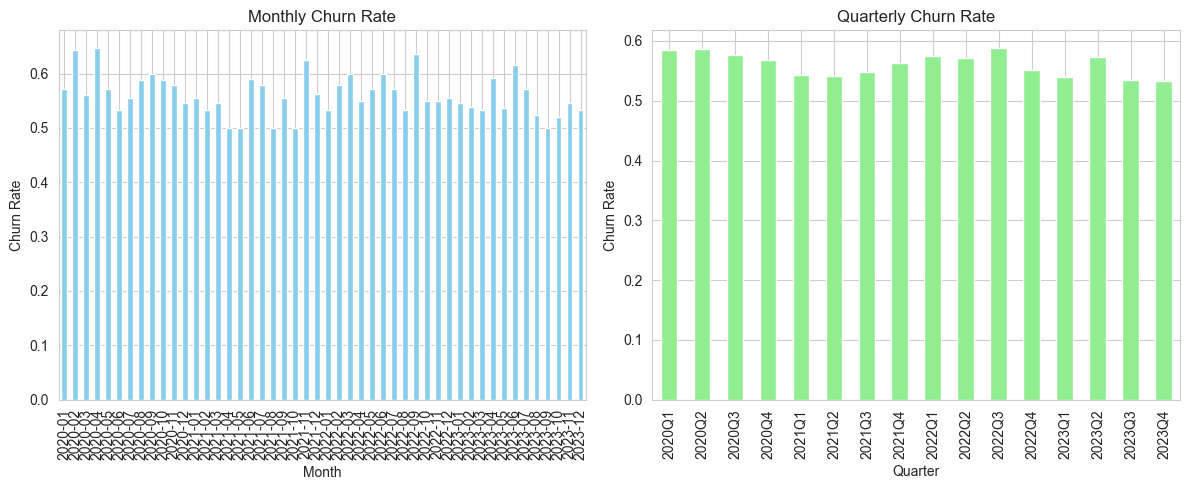

In [3]:
# Visualize churn rates
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
monthly_churn.plot(kind='bar', color='skyblue')
plt.title('Monthly Churn Rate')
plt.xlabel('Month')
plt.ylabel('Churn Rate')

plt.subplot(1, 2, 2)
quarterly_churn.plot(kind='bar', color='lightgreen')
plt.title('Quarterly Churn Rate')
plt.xlabel('Quarter')
plt.ylabel('Churn Rate')

plt.tight_layout()
plt.show()

Limitations of Simple Churn Rate:

While useful, simple churn rate doesn't tell the whole story. It doesn't account for fluctuations over shorter periods or variations within different customer segments.

Rolling Churn Rate:

A rolling churn rate provides a more dynamic view. Let's calculate it over a 90-day window:

In [4]:
# Create a date range for the analysis period
date_range = pd.date_range(start=accounts_df['contract_start_date'].min(), end=accounts_df['contract_end_date'].max(), freq='D')

rolling_churn = []
for d in date_range:
    # Accounts that churned within the 90-day window
    churned_in_window = accounts_df[(accounts_df['contract_end_date'] >= d - pd.Timedelta(days=90)) & 
                                   (accounts_df['contract_end_date'] < d)]

    # Accounts that were active at the start of the 90-day window
    active_at_start = accounts_df[(accounts_df['contract_start_date'] <= d - pd.Timedelta(days=90)) & 
                                 ((accounts_df['contract_end_date'].isnull()) | (accounts_df['contract_end_date'] >= d))]
    
    if len(active_at_start) > 0:
        rolling_churn.append(len(churned_in_window) / len(active_at_start))
    else:
        rolling_churn.append(0)


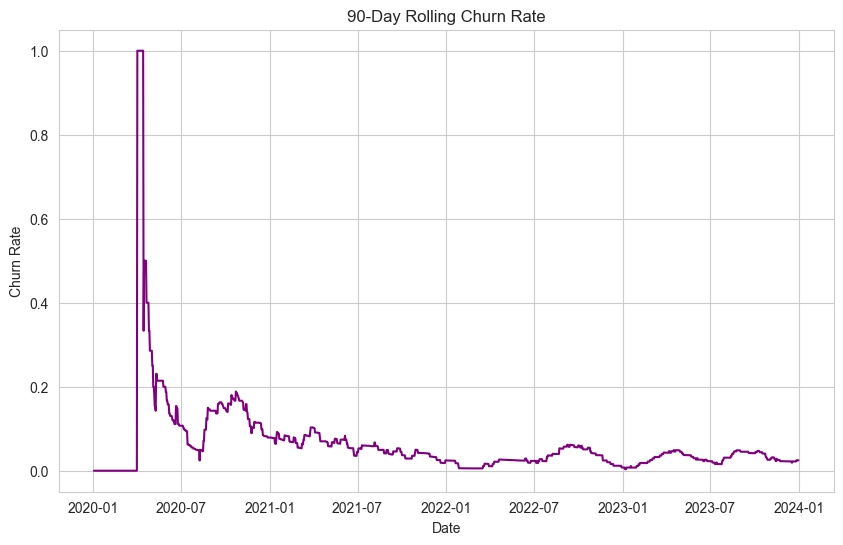

In [5]:
# Visualize rolling churn rate
plt.figure(figsize=(10, 6))
plt.plot(date_range, rolling_churn, color='purple')
plt.title('90-Day Rolling Churn Rate')
plt.xlabel('Date')
plt.ylabel('Churn Rate')
plt.show()


Calculating Account-Based Lifetime Value (AB-LTV)
AB-LTV is a crucial metric that tells you how much revenue you can expect from a specific account throughout your relationship. Here's how we can calculate it and then segment it for a comparative analysis:



In [6]:
# Calculate total revenue per account
total_revenue_per_account = invoices_df.groupby('account_id')['amount'].sum()

# Merge with accounts_df to get contract start and end dates
accounts_df = accounts_df.merge(total_revenue_per_account, on='account_id', how='left')
accounts_df.rename(columns={'amount': 'total_revenue'}, inplace=True)

# Calculate AB-LTV
def calculate_ab_ltv(df):
    """Calculates AB-LTV based on total revenue and contract duration."""
    # Calculate contract duration in days
    df['contract_duration_days'] = (df['contract_end_date'] - df['contract_start_date']).dt.days
    df['contract_duration_days'] = df['contract_duration_days'].fillna(0)  # Fill NaN with 0 for active accounts

    # Calculate AB-LTV
    df['ab_ltv'] = df['total_revenue'] / ((df['contract_duration_days'] / 365.25) + 1)  # Add 1 to avoid division by zero
    return df

accounts_df = calculate_ab_ltv(accounts_df)

# Display the updated DataFrame
print("Accounts DataFrame with AB-LTV:")
display(accounts_df.head())

Accounts DataFrame with AB-LTV:


,account_id,company_name,industry,employee_count,contract_start_date,contract_end_date,contract_start_month,contract_end_month,total_revenue,contract_duration_days,ab_ltv
0,231556ed-61e1-4482-8934-9161cb4b7b0c,Jensen-Todd,Technology,22,2023-04-06,2023-04-20,2023Q2,2023Q2,23344,14.0,22482.257086
1,39a00614-ae1a-46d8-9109-42aa70851c7e,Buchanan-Miller,Manufacturing,549,2023-05-21,NaT,2023Q2,NaT,13005,0.0,13005.000000
2,8bd41f7f-02b9-482a-b95d-5034de8901c1,Guzman and Sons,Retail,607,2020-01-07,2020-03-25,2020Q1,2020Q1,30733,78.0,25324.824027
3,8d186987-8b79-4315-b1b8-770bb2ba1e8c,Tran-Willis,Retail,114,2020-11-22,2021-06-29,2020Q4,2021Q2,11688,219.0,7306.875481
4,7aa28f2f-c23a-4da4-93eb-4958d7fb12f4,Sparks Ltd,Technology,43,2023-03-20,NaT,2023Q1,NaT,10223,0.0,10223.000000


Comparative Analysis: Segmenting AB-LTV
To extract more meaningful insights, let's segment AB-LTV by different factors like industry and employee count. This comparative approach will help you identify trends and patterns across various customer groups.

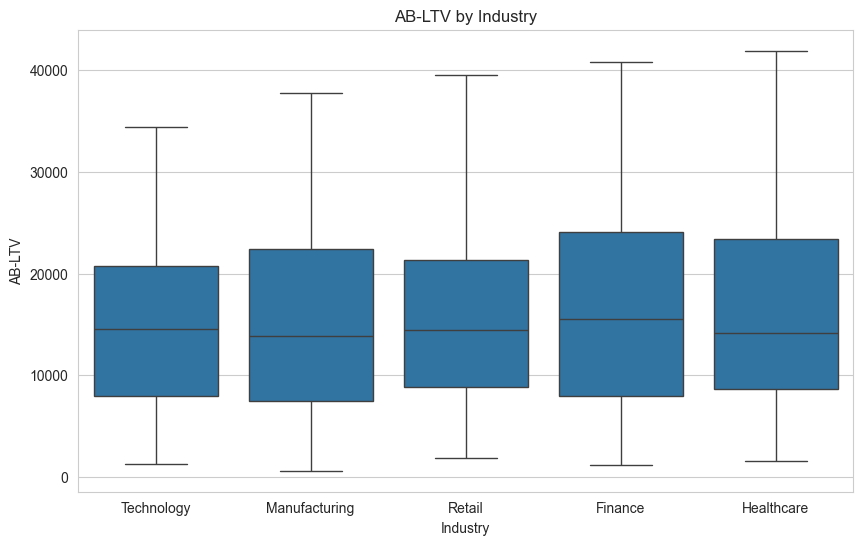

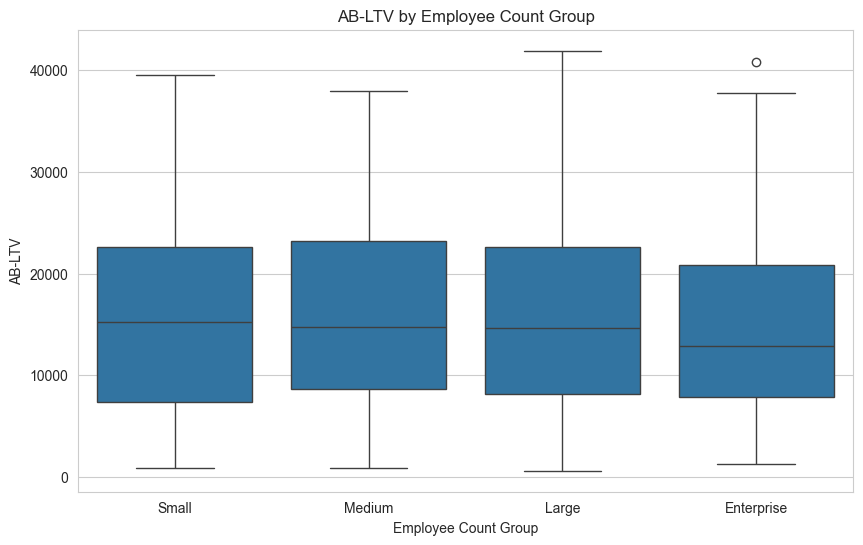

In [7]:
# Segment AB-LTV by industry
plt.figure(figsize=(10, 6))
sns.boxplot(x='industry', y='ab_ltv', data=accounts_df)
plt.title('AB-LTV by Industry')
plt.xlabel('Industry')
plt.ylabel('AB-LTV')
plt.show()

# Segment AB-LTV by employee count (using quantiles for grouping)
accounts_df['employee_count_group'] = pd.qcut(accounts_df['employee_count'], 4, labels=['Small', 'Medium', 'Large', 'Enterprise'])

plt.figure(figsize=(10, 6))
sns.boxplot(x='employee_count_group', y='ab_ltv', data=accounts_df)
plt.title('AB-LTV by Employee Count Group')
plt.xlabel('Employee Count Group')
plt.ylabel('AB-LTV')
plt.show()